In [72]:
import pandas as pd

# Players

In [73]:
players_data = pd.read_csv("../data/players.csv")
players_data.head()

,bioID,pos,firstseason,lastseason,height,weight,college,collegeOther,birthDate,deathDate
0,abrahta01w,C,0,0,74.0,190,George Washington,NaN,1975-09-27,0000-00-00
1,abrossv01w,F,0,0,74.0,169,Connecticut,NaN,1980-07-09,0000-00-00
2,adairje01w,C,0,0,76.0,197,George Washington,NaN,1986-12-19,0000-00-00
3,adamsda01w,F-C,0,0,73.0,239,Texas A&M,Jefferson College (JC),1989-02-19,0000-00-00
4,adamsjo01w,C,0,0,75.0,180,New Mexico,NaN,1981-05-24,0000-00-00


Analyzing missing values

In [74]:
print("Players' missing values:\n")
print(f"{players_data.isnull().sum()} \n")

Players' missing values:

bioID             0
pos              78
firstseason       0
lastseason        0
height            0
weight            0
college         167
collegeOther    882
birthDate         0
deathDate         0
dtype: int64 



Check unique values

In [75]:
unique_values = players_data.nunique()
print("Number of unique values:\n", unique_values)

Number of unique values:
 bioID           893
pos               7
firstseason       1
lastseason        1
height           21
weight          105
college         160
collegeOther     11
birthDate       764
deathDate         5
dtype: int64


Clean players dataset

In [76]:
# Remove players that don't have birthdate and dead players
players_data = players_data[players_data['birthDate'] != '0000-00-00']
players_data = players_data[players_data['deathDate'] == '0000-00-00']

# Transform birthDate in year
players_data['birthYear'] = pd.to_datetime(players_data['birthDate']).dt.year.astype(int)

# Drop columns that are not needed
players_data.drop(['birthDate', 'deathDate', 'firstseason', 'lastseason', 'college', 'collegeOther'], axis=1, inplace=True)
players_data.head()

,bioID,pos,height,weight,birthYear
0,abrahta01w,C,74.0,190,1975
1,abrossv01w,F,74.0,169,1980
2,adairje01w,C,76.0,197,1986
3,adamsda01w,F-C,73.0,239,1989
4,adamsjo01w,C,75.0,180,1981


Replace weights and heights that are at 0 with the average of their respective position

In [77]:
rows_with_zero_height_weight = players_data.loc[(players_data['height'] == 0) | (players_data['weight'] == 0)]

# Calculate average by position
mean_height = players_data[players_data['height'] != 0].groupby('pos')['height'].mean()
mean_weight = players_data[players_data['weight'] != 0].groupby('pos')['weight'].mean()

# Replace with average
for index, row in players_data.iterrows():
    if row['height'] == 0:
        players_data.at[index, 'height'] = mean_height.get(row['pos'], 0)
    if row['weight'] == 0:
        players_data.at[index, 'weight'] = mean_weight.get(row['pos'], 0)

In [78]:
# save data
players_data.to_csv('../data/clean_players.csv', index=True)

# Teams

In [79]:
teams_data = pd.read_csv("../data/teams.csv")
teams_data.head()

,year,lgID,tmID,franchID,confID,divID,rank,playoff,seeded,firstRound,semis,finals,name,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,o_oreb,o_dreb,o_reb,o_asts,o_pf,o_stl,o_to,o_blk,o_pts,d_fgm,d_fga,d_ftm,d_fta,d_3pm,d_3pa,d_oreb,d_dreb,d_reb,d_asts,d_pf,d_stl,d_to,d_blk,d_pts,tmORB,tmDRB,tmTRB,opptmORB,opptmDRB,opptmTRB,won,lost,GP,homeW,homeL,awayW,awayL,confW,confL,min,attend,arena
0,9,WNBA,ATL,ATL,EA,NaN,7,N,0,NaN,NaN,NaN,Atlanta Dream,895,2258,542,725,202,598,340,737,1077,492,796,285,593,142,2534,1014,2254,679,918,172,502,401,864,1265,684,726,310,561,134,2879,0,0,0,0,0,0,4,30,34,1,16,3,14,2,18,6825,141379,Philips Arena
1,10,WNBA,ATL,ATL,EA,NaN,2,Y,0,L,NaN,NaN,Atlanta Dream,1089,2428,569,755,114,374,404,855,1259,547,741,329,590,121,2861,996,2363,624,807,181,530,353,821,1174,615,700,347,601,133,2797,0,0,0,0,0,0,18,16,34,12,5,6,11,10,12,6950,120737,Philips Arena
2,1,WNBA,CHA,CHA,EA,NaN,8,N,0,NaN,NaN,NaN,Charlotte Sting,812,1903,431,577,131,386,305,630,935,551,713,222,496,90,2186,879,1930,533,716,138,423,326,664,990,596,596,259,426,123,2429,0,0,0,0,0,0,8,24,32,5,11,3,13,5,16,6475,90963,Charlotte Coliseum
3,2,WNBA,CHA,CHA,EA,NaN,4,Y,0,W,W,L,Charlotte Sting,746,1780,410,528,153,428,309,639,948,467,605,217,474,114,2055,732,1846,431,562,114,369,344,567,911,443,579,257,447,124,2009,0,0,0,0,0,0,18,14,32,11,5,7,9,15,6,6500,105525,Charlotte Coliseum
4,3,WNBA,CHA,CHA,EA,NaN,2,Y,0,L,NaN,NaN,Charlotte Sting,770,1790,490,663,211,527,302,653,955,496,647,241,408,105,2241,778,1807,444,598,133,372,295,620,915,489,600,208,424,103,2133,0,0,0,0,0,0,18,14,32,11,5,7,9,12,9,6450,106670,Charlotte Coliseum


Analyze missing values

In [80]:
# Show all columns and rows
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

print("Teams' missing values:\n")
print(f"{teams_data.isnull().sum()} \n")

Teams' missing values:

year            0
lgID            0
tmID            0
franchID        0
confID          0
divID         142
rank            0
playoff         0
seeded          0
firstRound     62
semis         104
finals        122
name            0
o_fgm           0
o_fga           0
o_ftm           0
o_fta           0
o_3pm           0
o_3pa           0
o_oreb          0
o_dreb          0
o_reb           0
o_asts          0
o_pf            0
o_stl           0
o_to            0
o_blk           0
o_pts           0
d_fgm           0
d_fga           0
d_ftm           0
d_fta           0
d_3pm           0
d_3pa           0
d_oreb          0
d_dreb          0
d_reb           0
d_asts          0
d_pf            0
d_stl           0
d_to            0
d_blk           0
d_pts           0
tmORB           0
tmDRB           0
tmTRB           0
opptmORB        0
opptmDRB        0
opptmTRB        0
won             0
lost            0
GP              0
homeW           0
homeL           0
away

Check unique values

In [81]:
unique_values = teams_data.nunique()
print("Number of unique values:\n", unique_values)

Number of unique values:
 year           10
lgID            1
tmID           20
franchID       18
confID          2
divID           0
rank            8
playoff         2
seeded          1
firstRound      2
semis           2
finals          2
name           20
o_fgm         116
o_fga         129
o_ftm         104
o_fta         111
o_3pm          94
o_3pa         122
o_oreb         97
o_dreb        110
o_reb         119
o_asts        101
o_pf          101
o_stl          89
o_to          105
o_blk          72
o_pts         134
d_fgm         113
d_fga         127
d_ftm         108
d_fta         116
d_3pm          82
d_3pa         115
d_oreb         85
d_dreb        110
d_reb         113
d_asts        100
d_pf           98
d_stl          78
d_to          102
d_blk          66
d_pts         131
tmORB           1
tmDRB           1
tmTRB           1
opptmORB        1
opptmDRB        1
opptmTRB        1
won            25
lost           26
GP              2
homeW          15
homeL          15
aw

Clean teams dataset

In [82]:
teams_data.drop(['lgID', 'rank', 'franchID', 'divID', 'seeded', 'name', 'tmORB', 'tmDRB', 'tmTRB', 'opptmORB', 'opptmDRB', 'opptmTRB', 'arena', 'attend'], axis=1, inplace=True)
teams_data.head()

,year,tmID,confID,playoff,firstRound,semis,finals,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,o_oreb,o_dreb,o_reb,o_asts,o_pf,o_stl,o_to,o_blk,o_pts,d_fgm,d_fga,d_ftm,d_fta,d_3pm,d_3pa,d_oreb,d_dreb,d_reb,d_asts,d_pf,d_stl,d_to,d_blk,d_pts,won,lost,GP,homeW,homeL,awayW,awayL,confW,confL,min
0,9,ATL,EA,N,NaN,NaN,NaN,895,2258,542,725,202,598,340,737,1077,492,796,285,593,142,2534,1014,2254,679,918,172,502,401,864,1265,684,726,310,561,134,2879,4,30,34,1,16,3,14,2,18,6825
1,10,ATL,EA,Y,L,NaN,NaN,1089,2428,569,755,114,374,404,855,1259,547,741,329,590,121,2861,996,2363,624,807,181,530,353,821,1174,615,700,347,601,133,2797,18,16,34,12,5,6,11,10,12,6950
2,1,CHA,EA,N,NaN,NaN,NaN,812,1903,431,577,131,386,305,630,935,551,713,222,496,90,2186,879,1930,533,716,138,423,326,664,990,596,596,259,426,123,2429,8,24,32,5,11,3,13,5,16,6475
3,2,CHA,EA,Y,W,W,L,746,1780,410,528,153,428,309,639,948,467,605,217,474,114,2055,732,1846,431,562,114,369,344,567,911,443,579,257,447,124,2009,18,14,32,11,5,7,9,15,6,6500
4,3,CHA,EA,Y,L,NaN,NaN,770,1790,490,663,211,527,302,653,955,496,647,241,408,105,2241,778,1807,444,598,133,372,295,620,915,489,600,208,424,103,2133,18,14,32,11,5,7,9,12,9,6450


In [83]:
# save data
teams_data.to_csv('../data/clean_teams.csv', index=True)

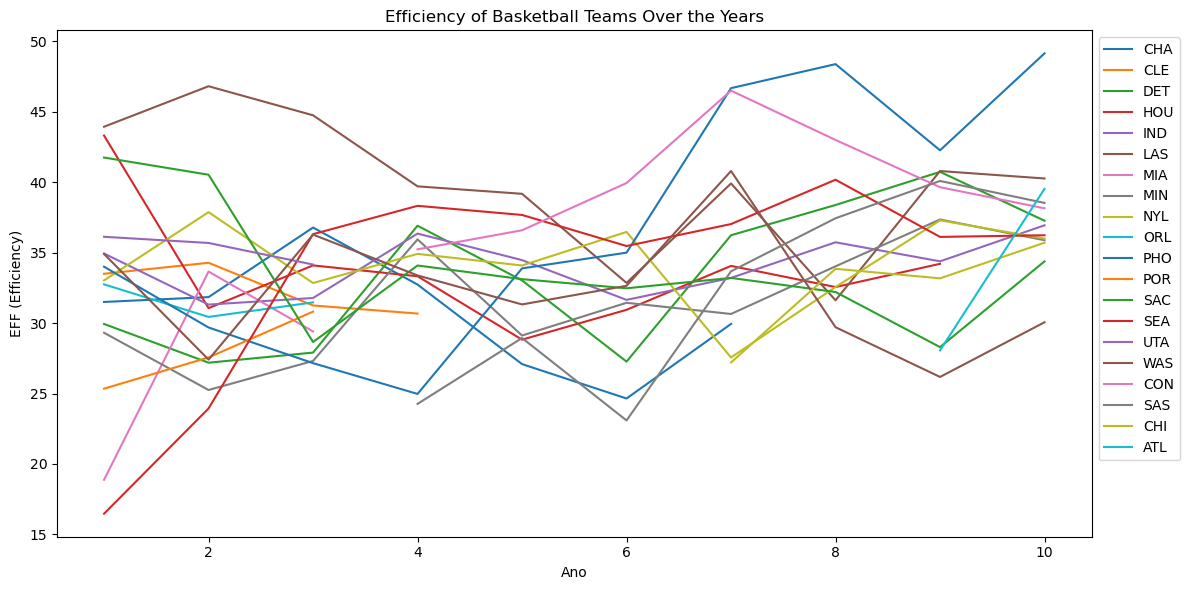

In [84]:
import matplotlib.pyplot as plt

teams_data = pd.read_csv("../data/clean_teams.csv")
teams_data['EFF'] = (teams_data['o_pts'] + teams_data['o_reb'] + teams_data['o_asts'] + teams_data['o_stl'] + teams_data['o_blk'] - teams_data['o_fga'] - teams_data['o_fta'] - teams_data['o_to']) / teams_data['GP']
teams_data= teams_data.sort_values(by=['year', 'tmID'])

plt.figure(figsize=(12, 6))
for equipa in teams_data['tmID'].unique():
    data_equipa = teams_data[teams_data['tmID'] == equipa]
    plt.plot(data_equipa['year'], data_equipa['EFF'], label=equipa)

plt.xlabel('Ano')
plt.ylabel('EFF (Efficiency)')
plt.title('Efficiency of Basketball Teams Over the Years')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

# Players_teams

In [85]:
players_teams_data = pd.read_csv("../data/players_teams.csv")
players_teams_data.head()

,playerID,year,stint,tmID,lgID,GP,GS,minutes,points,oRebounds,dRebounds,rebounds,assists,steals,blocks,turnovers,PF,fgAttempted,fgMade,ftAttempted,ftMade,threeAttempted,threeMade,dq,PostGP,PostGS,PostMinutes,PostPoints,PostoRebounds,PostdRebounds,PostRebounds,PostAssists,PostSteals,PostBlocks,PostTurnovers,PostPF,PostfgAttempted,PostfgMade,PostftAttempted,PostftMade,PostthreeAttempted,PostthreeMade,PostDQ
0,abrossv01w,2,0,MIN,WNBA,26,23,846,343,43,131,174,53,42,9,85,70,293,114,132,96,76,19,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,abrossv01w,3,0,MIN,WNBA,27,27,805,314,45,101,146,60,42,10,92,73,316,119,116,56,60,20,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,abrossv01w,4,0,MIN,WNBA,30,25,792,318,44,97,141,82,44,11,90,79,285,112,98,69,82,25,0,3,3,69,23,1,4,5,4,4,1,8,8,22,6,8,8,7,3,0
3,abrossv01w,5,0,MIN,WNBA,22,11,462,146,17,57,74,45,30,2,43,42,139,49,46,28,53,20,0,2,2,67,20,3,6,9,3,1,2,3,7,23,8,4,2,8,2,0
4,abrossv01w,6,0,MIN,WNBA,31,31,777,304,29,78,107,60,48,6,80,86,276,109,73,53,82,33,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Analyze missing values

In [86]:
print("Players Teams' missing values:\n")
print(f"{players_teams_data.isnull().sum()} \n")

Players Teams' missing values:

playerID              0
year                  0
stint                 0
tmID                  0
lgID                  0
GP                    0
GS                    0
minutes               0
points                0
oRebounds             0
dRebounds             0
rebounds              0
assists               0
steals                0
blocks                0
turnovers             0
PF                    0
fgAttempted           0
fgMade                0
ftAttempted           0
ftMade                0
threeAttempted        0
threeMade             0
dq                    0
PostGP                0
PostGS                0
PostMinutes           0
PostPoints            0
PostoRebounds         0
PostdRebounds         0
PostRebounds          0
PostAssists           0
PostSteals            0
PostBlocks            0
PostTurnovers         0
PostPF                0
PostfgAttempted       0
PostfgMade            0
PostftAttempted       0
PostftMade            0
Postthre

Check unique values

In [87]:
unique_values = players_teams_data.nunique()
print("Number of unique values:\n", unique_values)

Number of unique values:
 playerID              555
year                   10
stint                   4
tmID                   20
lgID                    1
GP                     34
GS                     35
minutes               899
points                530
oRebounds             111
dRebounds             203
rebounds              270
assists               174
steals                 87
blocks                 77
turnovers             118
PF                    137
fgAttempted           456
fgMade                225
ftAttempted           200
ftMade                165
threeAttempted        187
threeMade              82
dq                      8
PostGP                 12
PostGS                 12
PostMinutes           254
PostPoints            138
PostoRebounds          29
PostdRebounds          53
PostRebounds           74
PostAssists            49
PostSteals             21
PostBlocks             20
PostTurnovers          33
PostPF                 39
PostfgAttempted       118
PostfgMade  

Clean players_teams dataset

In [88]:
players_teams_data.drop(["lgID"], axis=1, inplace=True)
players_teams_data.head()

,playerID,year,stint,tmID,GP,GS,minutes,points,oRebounds,dRebounds,rebounds,assists,steals,blocks,turnovers,PF,fgAttempted,fgMade,ftAttempted,ftMade,threeAttempted,threeMade,dq,PostGP,PostGS,PostMinutes,PostPoints,PostoRebounds,PostdRebounds,PostRebounds,PostAssists,PostSteals,PostBlocks,PostTurnovers,PostPF,PostfgAttempted,PostfgMade,PostftAttempted,PostftMade,PostthreeAttempted,PostthreeMade,PostDQ
0,abrossv01w,2,0,MIN,26,23,846,343,43,131,174,53,42,9,85,70,293,114,132,96,76,19,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,abrossv01w,3,0,MIN,27,27,805,314,45,101,146,60,42,10,92,73,316,119,116,56,60,20,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,abrossv01w,4,0,MIN,30,25,792,318,44,97,141,82,44,11,90,79,285,112,98,69,82,25,0,3,3,69,23,1,4,5,4,4,1,8,8,22,6,8,8,7,3,0
3,abrossv01w,5,0,MIN,22,11,462,146,17,57,74,45,30,2,43,42,139,49,46,28,53,20,0,2,2,67,20,3,6,9,3,1,2,3,7,23,8,4,2,8,2,0
4,abrossv01w,6,0,MIN,31,31,777,304,29,78,107,60,48,6,80,86,276,109,73,53,82,33,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [89]:
# save data
players_teams_data.to_csv('../data/clean_players_teams.csv', index=True)

In [90]:
teams_df = pd.read_csv("../data/clean_teams.csv")
players_df = pd.read_csv("../data/clean_players.csv")
players_teams_df = pd.read_csv("../data/clean_players_teams.csv")

merged_df = teams_df.merge(players_teams_df, on=['year', 'tmID'], how='inner')

# Aggregate player statistics by team and year
agg_df = merged_df.groupby(['year', 'tmID']).agg({
    'points': 'sum',
    'rebounds': 'sum',
    'assists': 'sum',
    # Add other player-level statistics as needed
}).reset_index()


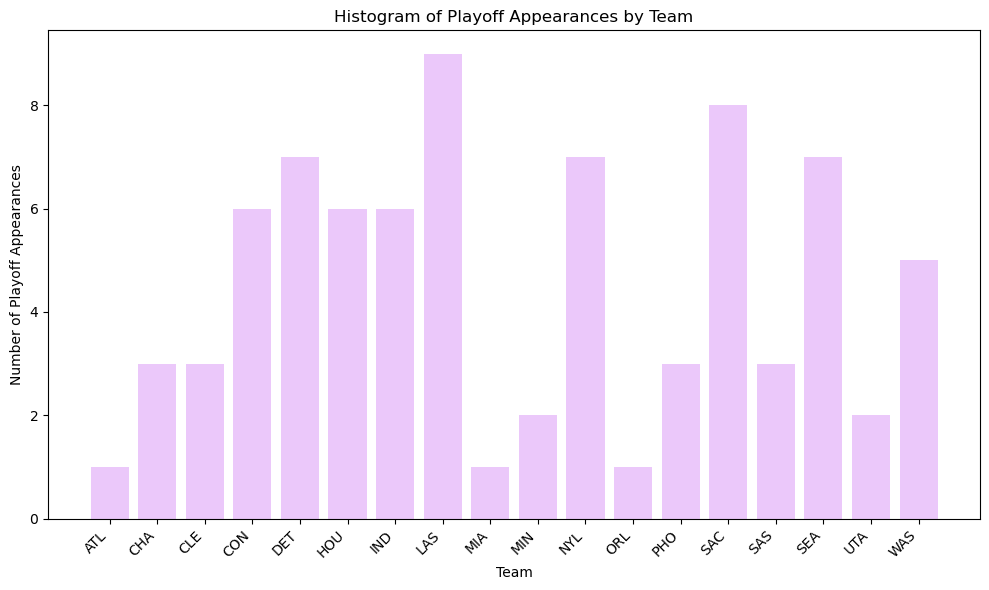

Text(0, 0.5, 'Count')

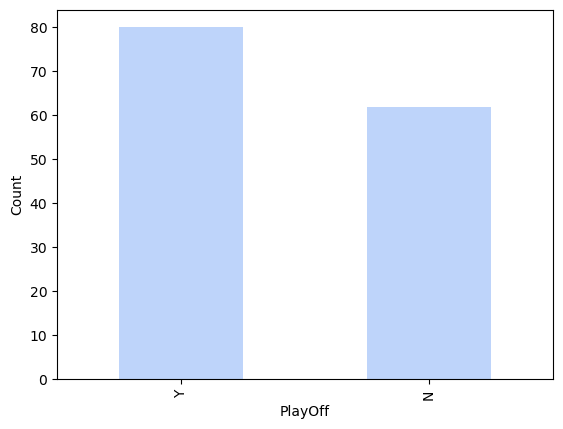

In [91]:
import matplotlib.pyplot as plt

df = pd.read_csv("../data/clean_teams.csv")

playoff_data = df[['year', 'tmID', 'playoff']]

playoff_teams = playoff_data[playoff_data['playoff'] == 'Y']

playoff_counts = playoff_teams.groupby('tmID').size()

plt.figure(figsize=(10, 6))
plt.bar(playoff_counts.index, playoff_counts.values, color='#ebc8fa')
plt.xlabel('Team')
plt.ylabel('Number of Playoff Appearances')
plt.title('Histogram of Playoff Appearances by Team')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


df["playoff"].value_counts().plot.bar(color="#bed4fa")
plt.xlabel("PlayOff")
plt.ylabel("Count")


# Coaches

In [92]:
coaches_data = pd.read_csv("../data/coaches.csv")
coaches_data.head()

,coachID,year,tmID,lgID,stint,won,lost,post_wins,post_losses
0,adamsmi01w,5,WAS,WNBA,0,17,17,1,2
1,adubari99w,1,NYL,WNBA,0,20,12,4,3
2,adubari99w,2,NYL,WNBA,0,21,11,3,3
3,adubari99w,3,NYL,WNBA,0,18,14,4,4
4,adubari99w,4,NYL,WNBA,0,16,18,0,0


Analyze missing values

In [93]:
print("Coaches' missing values:\n")
print(f"{coaches_data.isnull().sum()} \n")

Coaches' missing values:

coachID        0
year           0
tmID           0
lgID           0
stint          0
won            0
lost           0
post_wins      0
post_losses    0
dtype: int64 



Check unique values

In [94]:
unique_values = coaches_data.nunique()
print("Number of unique values:\n", unique_values)

Number of unique values:
 coachID        57
year           10
tmID           20
lgID            1
stint           3
won            29
lost           28
post_wins       8
post_losses     6
dtype: int64


Clean coaches dataset

In [95]:
coaches_data.drop(['lgID'], axis=1, inplace=True)
coaches_data.head()

,coachID,year,tmID,stint,won,lost,post_wins,post_losses
0,adamsmi01w,5,WAS,0,17,17,1,2
1,adubari99w,1,NYL,0,20,12,4,3
2,adubari99w,2,NYL,0,21,11,3,3
3,adubari99w,3,NYL,0,18,14,4,4
4,adubari99w,4,NYL,0,16,18,0,0


In [96]:
# save data
coaches_data.to_csv('../data/clean_coaches.csv', index=True)

# Awards_players

In [97]:
awards_data = pd.read_csv("../data/awards_players.csv")
awards_data.head()

,playerID,award,year,lgID
0,thompti01w,All-Star Game Most Valuable Player,1,WNBA
1,leslili01w,All-Star Game Most Valuable Player,2,WNBA
2,leslili01w,All-Star Game Most Valuable Player,3,WNBA
3,teaslni01w,All-Star Game Most Valuable Player,4,WNBA
4,swoopsh01w,All-Star Game Most Valuable Player,6,WNBA


Analyze missing values

In [98]:
print("Awards' missing values:\n")
print(f"{awards_data.isnull().sum()} \n")

Awards' missing values:

playerID    0
award       0
year        0
lgID        0
dtype: int64 



Check unique values

In [99]:
unique_values = awards_data.nunique()
print("Number of unique values:\n", unique_values)

Number of unique values:
 playerID    58
award       12
year        10
lgID         1
dtype: int64


Clean awards dataset

In [100]:
awards_data.drop(["lgID"], axis=1, inplace=True)
awards_data.head()

,playerID,award,year
0,thompti01w,All-Star Game Most Valuable Player,1
1,leslili01w,All-Star Game Most Valuable Player,2
2,leslili01w,All-Star Game Most Valuable Player,3
3,teaslni01w,All-Star Game Most Valuable Player,4
4,swoopsh01w,All-Star Game Most Valuable Player,6


In [101]:
# save data
coaches_data.to_csv('../data/clean_awards.csv', index=True)

# Teams_post

In [102]:
teams_post_data = pd.read_csv("../data/teams_post.csv")
teams_post_data.head()

,year,tmID,lgID,W,L
0,1,HOU,WNBA,6,0
1,1,ORL,WNBA,1,2
2,1,CLE,WNBA,3,3
3,1,WAS,WNBA,0,2
4,1,NYL,WNBA,4,3


Analyze missing values

In [103]:
print("Teams Post's missing values:\n")
print(f"{teams_post_data.isnull().sum()} \n")

Teams Post's missing values:

year    0
tmID    0
lgID    0
W       0
L       0
dtype: int64 



Check unique values

In [104]:
unique_values = teams_post_data.nunique()
print("Number of unique values:\n", unique_values)

Number of unique values:
 year    10
tmID    18
lgID     1
W        8
L        7
dtype: int64


Clean teams_post dataset

In [105]:
teams_post_data.drop(["lgID"], axis=1, inplace=True)
teams_post_data.head()

,year,tmID,W,L
0,1,HOU,6,0
1,1,ORL,1,2
2,1,CLE,3,3
3,1,WAS,0,2
4,1,NYL,4,3


In [106]:
# save data
teams_post_data.to_csv('../data/clean_teams_post.csv', index=True)

# Series_post

In [107]:
series_post_data = pd.read_csv("../data/series_post.csv")
series_post_data.head()

,year,round,series,tmIDWinner,lgIDWinner,tmIDLoser,lgIDLoser,W,L
0,1,FR,A,CLE,WNBA,ORL,WNBA,2,1
1,1,FR,B,NYL,WNBA,WAS,WNBA,2,0
2,1,FR,C,LAS,WNBA,PHO,WNBA,2,0
3,1,FR,D,HOU,WNBA,SAC,WNBA,2,0
4,1,CF,E,HOU,WNBA,LAS,WNBA,2,0


Analyze missing values

In [108]:
print("Series Post's missing values:\n")
print(f"{series_post_data.isnull().sum()} \n")

Series Post's missing values:

year          0
round         0
series        0
tmIDWinner    0
lgIDWinner    0
tmIDLoser     0
lgIDLoser     0
W             0
L             0
dtype: int64 



Check unique values

In [109]:
unique_values = series_post_data.nunique()
print("Number of unique values:\n", unique_values)

Number of unique values:
 year          10
round          3
series         7
tmIDWinner    14
lgIDWinner     1
tmIDLoser     18
lgIDLoser      1
W              2
L              3
dtype: int64


Clean series_post dataset

In [110]:
series_post_data.drop(["lgIDWinner", "lgIDLoser"], axis=1, inplace=True)
series_post_data.head()

,year,round,series,tmIDWinner,tmIDLoser,W,L
0,1,FR,A,CLE,ORL,2,1
1,1,FR,B,NYL,WAS,2,0
2,1,FR,C,LAS,PHO,2,0
3,1,FR,D,HOU,SAC,2,0
4,1,CF,E,HOU,LAS,2,0


In [111]:
# save data
series_post_data.to_csv('../data/clean_series_post.csv', index=True)